# 01. Predicción de partidas de League of Legends con un MLP

**Douglas Pérez**  
**Carnet 22003865**

## 1. Introducción y objetivo

Quiero estimar si el equipo azul ganará una partida usando únicamente lo que ocurrió en los primeros diez minutos. Elegí League of Legends porque una ventaja temprana se puede medir con oro, experiencia y objetivos, pero el resultado todavía puede cambiar.

Voy a comparar dos redes totalmente conectadas con una regresión logística. Me interesa ver si el MLP mejora la predicción y qué casos siguen siendo difíciles.

El conjunto contiene partidas clasificatorias de nivel alto. Lo descargué de [League of Legends Diamond Ranked Games (10 min), publicado por Bobbyscience en Kaggle](https://www.kaggle.com/datasets/bobbyscience/league-of-legends-diamond-ranked-games-10-min).
Lo uso para estudiar esta muestra. El comportamiento de otros rangos y parches queda fuera de la evaluación.

## 2. Carga y exploración de datos

Voy a usar Python, PyTorch y scikit-learn en Google Colab. El entrenamiento está configurado para CPU porque los datos caben en memoria y las redes son pequeñas. Fijo la semilla para facilitar la reproducción.

In [1]:
import hashlib
import io
import os
import random
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    log_loss,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEMILLA = 42
DISPOSITIVO = torch.device("cpu")
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(f"PyTorch {torch.__version__} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
print(f"Dispositivo: {DISPOSITIVO} | Semilla: {SEMILLA}")

PyTorch 2.15.0+cpu | scikit-learn 1.9.1 | pandas 3.1.1 | NumPy 2.5.5 | Matplotlib 3.11.2
Dispositivo: cpu | Semilla: 42


Descargo la versión 1 del archivo y compruebo la huella del CSV para usar la misma muestra al repetir el experimento. Si ya descargué el ZIP desde Kaggle, puedo subirlo a Colab y guardarlo con el nombre **league-of-legends-v1.zip** en el directorio de trabajo. También puedo indicar su ruta en la variable de entorno **LOL_DATASET_ZIP**.

In [2]:
URL_DATOS = (
    "https://www.kaggle.com/api/v1/datasets/download/bobbyscience/"
    "league-of-legends-diamond-ranked-games-10-min?datasetVersionNumber=1"
)
CSV_DATOS = "high_diamond_ranked_10min.csv"
HUELLA_CSV = "82b2e23279097c2dac616e966eb2911711c428d41b6382b4cdb15da4892f9ca6"
ruta_zip = Path(os.environ.get("LOL_DATASET_ZIP", "league-of-legends-v1.zip"))

if ruta_zip.is_file():
    archivo_zip = ruta_zip.read_bytes()
else:
    solicitud = Request(URL_DATOS, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(solicitud, timeout=90) as respuesta:
        archivo_zip = respuesta.read()

# Leo directamente el CSV del ZIP para trabajar con el archivo original.
with zipfile.ZipFile(io.BytesIO(archivo_zip)) as paquete:
    contenido_csv = paquete.read(CSV_DATOS)
if hashlib.sha256(contenido_csv).hexdigest() != HUELLA_CSV:
    raise ValueError("El CSV no coincide con la versión 1 de Kaggle.")

datos = pd.read_csv(io.BytesIO(contenido_csv))
assert datos.shape == (9879, 40)
assert datos["gameId"].is_unique and set(datos["blueWins"]) == {0, 1}
assert datos.isna().sum().sum() == 0
print(f"{len(datos):,} partidas | {datos.shape[1]} columnas | 0 valores faltantes")
display(datos[["gameId", "blueWins", "blueGoldDiff", "blueKills", "redKills"]].head())

9,879 partidas | 40 columnas | 0 valores faltantes


,gameId,blueWins,blueGoldDiff,blueKills,redKills
0,4519157822,0,643,9,6
1,4523371949,0,-2908,5,5
2,4521474530,0,-1172,7,11
3,4524384067,0,-1321,4,5
4,4436033771,0,-1004,6,6


La etiqueta es **blueWins**, donde 0 indica victoria del equipo rojo y 1 indica victoria del azul. Reviso cuántas partidas hay por clase y cómo se distribuye la diferencia de oro. La comparación de oro por ganador la hago más adelante con el conjunto de entrenamiento.

,blueGoldDiff,blueExperienceDiff,blueKills,redKills
count,9879.0,9879.0,9879.0,9879.0
mean,14.4,-33.6,6.2,6.1
std,2453.3,1920.4,3.0,2.9
min,-10830.0,-9333.0,0.0,0.0
25%,-1585.5,-1290.5,4.0,4.0
50%,14.0,-28.0,6.0,6.0
75%,1596.0,1212.0,8.0,8.0
max,11467.0,8348.0,22.0,22.0


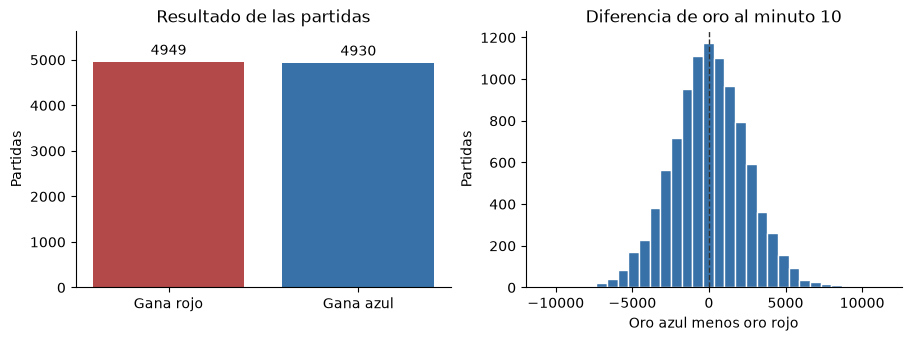

In [3]:
nombres_clases = ["Gana rojo", "Gana azul"]
resumen_clases = datos["blueWins"].value_counts().sort_index()
display(datos[["blueGoldDiff", "blueExperienceDiff", "blueKills", "redKills"]]
        .describe().round(1))

fig, ejes = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained")
barras = ejes[0].bar(nombres_clases, resumen_clases.values, color=["#b44949", "#3771a8"])
ejes[0].bar_label(barras, padding=3)
ejes[0].set(ylim=(0, max(resumen_clases) * 1.14), ylabel="Partidas",
            title="Resultado de las partidas")
ejes[1].hist(datos["blueGoldDiff"], bins=32, color="#3771a8", edgecolor="white")
ejes[1].axvline(0, color="#303030", linestyle="--", linewidth=1)
ejes[1].set(xlabel="Oro azul menos oro rojo", ylabel="Partidas",
            title="Diferencia de oro al minuto 10")
plt.show()

## 3. Preprocesamiento y división

Represento la ventaja del equipo azul con diferencias frente al rojo para oro, experiencia, bajas, asistencias, visión y objetivos. Conservo la primera baja como una variable binaria. Excluyo el identificador, las estadísticas duplicadas que describen la misma ventaja y la etiqueta.

Divido por partida con estratificación para mantener proporciones similares de victorias. Uso aproximadamente 70 % para entrenamiento, 15 % para validación y 15 % para prueba. Calculo la media y la desviación para estandarizar únicamente con entrenamiento. La validación sirve para elegir el MLP y la prueba queda reservada para la evaluación final.

In [4]:
diferencias = {
    "oro": "TotalGold",
    "experiencia": "TotalExperience",
    "bajas": "Kills",
    "asistencias": "Assists",
    "guardianes_colocados": "WardsPlaced",
    "guardianes_destruidos": "WardsDestroyed",
    "dragones": "Dragons",
    "heraldos": "Heralds",
    "torres": "TowersDestroyed",
    "nivel_promedio": "AvgLevel",
    "subditos_linea": "TotalMinionsKilled",
    "subditos_jungla": "TotalJungleMinionsKilled",
}
variables = pd.DataFrame({
    nombre: datos[f"blue{columna}"] - datos[f"red{columna}"]
    for nombre, columna in diferencias.items()
})
variables["primera_baja_azul"] = datos["blueFirstBlood"]
etiquetas = datos["blueWins"].to_numpy()

indices_desarrollo, indices_prueba = train_test_split(
    np.arange(len(datos)), test_size=0.15, stratify=etiquetas, random_state=SEMILLA
)
indices_entrenamiento, indices_validacion = train_test_split(
    indices_desarrollo, test_size=0.15 / 0.85,
    stratify=etiquetas[indices_desarrollo], random_state=SEMILLA,
)
# Cada partida debe quedar en una sola partición.
indices = np.concatenate([indices_entrenamiento, indices_validacion, indices_prueba])
assert len(np.unique(indices)) == len(datos)

escalador = StandardScaler()
x_entrenamiento = escalador.fit_transform(variables.iloc[indices_entrenamiento]).astype("float32")
x_validacion = escalador.transform(variables.iloc[indices_validacion]).astype("float32")
x_prueba = escalador.transform(variables.iloc[indices_prueba]).astype("float32")
y_entrenamiento = etiquetas[indices_entrenamiento]
y_validacion = etiquetas[indices_validacion]
y_prueba = etiquetas[indices_prueba]
assert np.allclose(x_entrenamiento.mean(axis=0), 0, atol=1e-5)

resumen_particiones = pd.DataFrame(
    {
        "Partidas": [len(y) for y in (y_entrenamiento, y_validacion, y_prueba)],
        "Victorias del azul (%)": [100 * y.mean() for y in (y_entrenamiento, y_validacion, y_prueba)],
    },
    index=["Entrenamiento", "Validación", "Prueba"],
)
display(resumen_particiones.round(2))

,Partidas,Victorias del azul (%)
Entrenamiento,6915,49.91
Validación,1482,49.87
Prueba,1482,49.93


Con la partición de entrenamiento reviso cómo cambia la diferencia de oro según el ganador. Esto me da una referencia para entender por qué una ventaja temprana aporta información y por qué hay casos en los que los dos resultados siguen siendo posibles.

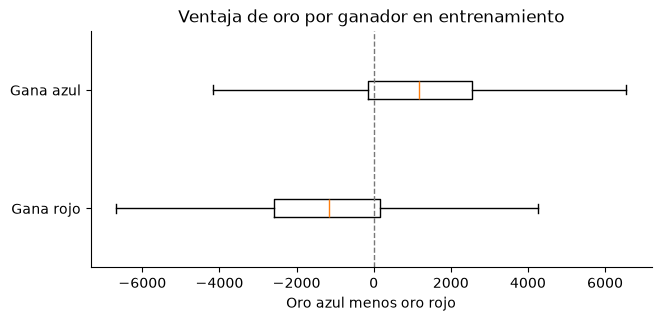

In [5]:
oro_entrenamiento = variables.iloc[indices_entrenamiento]["oro"].to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 3.1), layout="constrained")
ax.boxplot(
    [oro_entrenamiento[y_entrenamiento == clase] for clase in (0, 1)],
    tick_labels=nombres_clases,
    showfliers=False,
    orientation="horizontal",
)
ax.axvline(0, color="#777777", linestyle="--", linewidth=1)
ax.set(title="Ventaja de oro por ganador en entrenamiento",
       xlabel="Oro azul menos oro rojo")
plt.show()

## 4. Definición del modelo

El MLP recibe trece variables y devuelve un logit que convierto en probabilidad con sigmoide al evaluar. Empiezo con una capa oculta de 32 neuronas y pruebo una segunda red de 64 y 32 neuronas con dropout de 0.20. Uso ReLU en las capas ocultas para que la red pueda aprender relaciones no lineales.

Incluyo una regresión logística como referencia. Usa las mismas variables y particiones, así puedo ver qué gano al agregar capas ocultas.

In [6]:
configuraciones = {
    "MLP de una capa": {"ocultas": (32,), "dropout": 0.0},
    "MLP de dos capas": {"ocultas": (64, 32), "dropout": 0.20},
}


def crear_mlp(n_entradas, ocultas, dropout):
    capas = []
    n_anterior = n_entradas
    for n_neuronas in ocultas:
        capas.extend([nn.Linear(n_anterior, n_neuronas), nn.ReLU()])
        if dropout > 0:
            capas.append(nn.Dropout(dropout))
        n_anterior = n_neuronas
    capas.append(nn.Linear(n_anterior, 1))
    return nn.Sequential(*capas)


for nombre, config in configuraciones.items():
    modelo = crear_mlp(variables.shape[1], **config)
    parametros = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"{nombre} | {parametros:,} parámetros entrenables")
    print(modelo, "\n")

MLP de una capa | 481 parámetros entrenables
Sequential(
  (0): Linear(in_features=13, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=1, bias=True)
) 

MLP de dos capas | 3,009 parámetros entrenables
Sequential(
  (0): Linear(in_features=13, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=32, out_features=1, bias=True)
) 



## 5. Entrenamiento y selección

Uso **BCEWithLogitsLoss** porque el resultado tiene dos clases y **Adam** para actualizar los pesos. Mantengo la misma tasa de aprendizaje, el mismo tamaño de lote y el mismo límite de épocas en los dos MLP. Guardo un checkpoint cada vez que mejora la pérdida de validación y detengo la red si pasan ocho épocas seguidas sin mejora.

Comparo los mejores checkpoints por su pérdida de validación. Después cargo el que obtenga el menor valor.

In [7]:
TASA_APRENDIZAJE = 0.001
TAMANO_LOTE = 256
MAX_EPOCAS = 50
PACIENCIA = 8
MEJORA_MINIMA = 1e-5
carpeta_checkpoints = Path(os.environ.get("LOL_CHECKPOINT_DIR", "checkpoints"))
carpeta_checkpoints.mkdir(parents=True, exist_ok=True)


def a_tensores(x, y):
    return (
        torch.as_tensor(x, dtype=torch.float32, device=DISPOSITIVO),
        torch.as_tensor(y, dtype=torch.float32, device=DISPOSITIVO),
    )


lotes_entrenamiento = TensorDataset(*a_tensores(x_entrenamiento, y_entrenamiento))
tensores_entrenamiento = a_tensores(x_entrenamiento, y_entrenamiento)
tensores_validacion = a_tensores(x_validacion, y_validacion)
criterio = nn.BCEWithLogitsLoss()


@torch.inference_mode()
def evaluar_tensores(modelo, tensores):
    modelo.eval()
    x, y = tensores
    logits = modelo(x).squeeze(-1)
    perdida = criterio(logits, y).item()
    probabilidades = torch.sigmoid(logits).cpu().numpy()
    aciertos = ((logits >= 0) == y.bool()).float().mean().item()
    return perdida, aciertos, probabilidades


def entrenar_mlp(modelo, ruta_checkpoint):
    optimizador = torch.optim.Adam(modelo.parameters(), lr=TASA_APRENDIZAJE)
    lotes = DataLoader(
        lotes_entrenamiento, batch_size=TAMANO_LOTE, shuffle=True,
        generator=torch.Generator().manual_seed(SEMILLA),
    )
    historial = []
    mejor_perdida = float("inf")
    mejor_epoca = 0

    for epoca in range(1, MAX_EPOCAS + 1):
        modelo.train()
        for x_lote, y_lote in lotes:
            optimizador.zero_grad()
            logits = modelo(x_lote).squeeze(-1)
            perdida = criterio(logits, y_lote)
            perdida.backward()
            optimizador.step()

        # Registro ambas curvas sin dropout para que se puedan comparar.
        loss_train, acc_train, _ = evaluar_tensores(modelo, tensores_entrenamiento)
        loss_val, acc_val, _ = evaluar_tensores(modelo, tensores_validacion)
        historial.append({
            "época": epoca, "loss_train": loss_train, "loss_val": loss_val,
            "acc_train": acc_train, "acc_val": acc_val,
        })

        if loss_val < mejor_perdida - MEJORA_MINIMA:
            mejor_perdida = loss_val
            mejor_epoca = epoca
            torch.save(modelo.state_dict(), ruta_checkpoint)
        if epoca - mejor_epoca >= PACIENCIA:
            break

    return pd.DataFrame(historial), mejor_epoca, mejor_perdida

In [8]:
referencia = LogisticRegression(max_iter=1000, random_state=SEMILLA)
referencia.fit(x_entrenamiento, y_entrenamiento)
prob_val_referencia = referencia.predict_proba(x_validacion)[:, 1]
loss_val_referencia = log_loss(y_validacion, prob_val_referencia, labels=[0, 1])

historiales = {}
resultados_validacion = []
rutas_checkpoints = {}
for numero, (nombre, config) in enumerate(configuraciones.items(), start=1):
    torch.manual_seed(SEMILLA)
    modelo = crear_mlp(variables.shape[1], **config).to(DISPOSITIVO)
    ruta = carpeta_checkpoints / f"mlp_{numero}_mejor.pt"
    historial, mejor_epoca, perdida = entrenar_mlp(modelo, ruta)
    historiales[nombre] = historial
    rutas_checkpoints[nombre] = ruta
    resultados_validacion.append({
        "Modelo": nombre, "Épocas ejecutadas": len(historial),
        "Mejor época": mejor_epoca, "Pérdida de validación": perdida,
        "Exactitud de validación": historial.loc[mejor_epoca - 1, "acc_val"],
    })

tabla_validacion = pd.DataFrame(resultados_validacion).sort_values("Pérdida de validación")
ganador = tabla_validacion.iloc[0]
nombre_elegido = ganador["Modelo"]
modelo_elegido = crear_mlp(variables.shape[1], **configuraciones[nombre_elegido]).to(DISPOSITIVO)
modelo_elegido.load_state_dict(
    torch.load(rutas_checkpoints[nombre_elegido], map_location=DISPOSITIVO, weights_only=True)
)
display(tabla_validacion.round(4))
print(f"Referencia logística en validación | Pérdida: {loss_val_referencia:.4f}")
print(f"MLP elegido: {nombre_elegido} | Checkpoint: época {int(ganador['Mejor época'])}")

,Modelo,Épocas ejecutadas,Mejor época,Pérdida de validación,Exactitud de validación
0,MLP de una capa,50,47,0.5245,0.7375
1,MLP de dos capas,31,23,0.5251,0.7422


Referencia logística en validación | Pérdida: 0.5207
MLP elegido: MLP de una capa | Checkpoint: época 47


## 6. Evaluación y resultados

Primero reviso las curvas para ver dónde deja de mejorar cada red. Luego comparo el checkpoint elegido y la regresión logística en las mismas partidas de prueba. Uso un umbral de 0.50 para decidir qué equipo gana y reporto exactitud, precisión, recall y F1 macro, además de la pérdida y ROC-AUC.

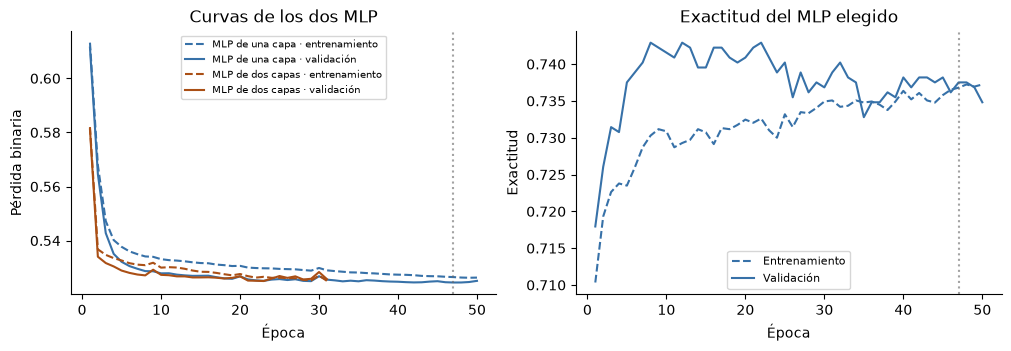

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
colores = ["#3771a8", "#aa4f15"]
for color, (nombre, historial) in zip(colores, historiales.items()):
    ejes[0].plot(historial["época"], historial["loss_train"], "--", color=color,
                 label=f"{nombre} · entrenamiento")
    ejes[0].plot(historial["época"], historial["loss_val"], color=color,
                 label=f"{nombre} · validación")
ejes[0].axvline(ganador["Mejor época"], color="#666666", alpha=0.6, linestyle=":")
ejes[0].set(xlabel="Época", ylabel="Pérdida binaria", title="Curvas de los dos MLP")
ejes[0].legend(fontsize=7)

historial_elegido = historiales[nombre_elegido]
ejes[1].plot(historial_elegido["época"], historial_elegido["acc_train"],
             "--", color=colores[0], label="Entrenamiento")
ejes[1].plot(historial_elegido["época"], historial_elegido["acc_val"],
             color=colores[0], label="Validación")
ejes[1].axvline(ganador["Mejor época"], color="#666666", alpha=0.6, linestyle=":")
ejes[1].set(xlabel="Época", ylabel="Exactitud", title="Exactitud del MLP elegido")
ejes[1].legend(fontsize=8)
plt.show()

,Pérdida,Exactitud,Precisión macro,Recall macro,F1 macro,ROC-AUC
MLP de una capa,0.5350,0.7126,0.7128,0.7126,0.7125,0.8028
Regresión logística,0.5288,0.7193,0.7194,0.7193,0.7193,0.8072


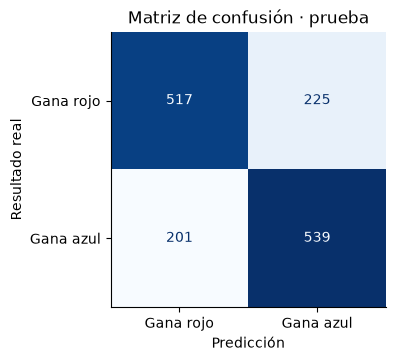

In [10]:
loss_prueba_mlp, _, prob_prueba_mlp = evaluar_tensores(
    modelo_elegido, a_tensores(x_prueba, y_prueba)
)
prob_prueba_referencia = referencia.predict_proba(x_prueba)[:, 1]
pred_prueba_mlp = (prob_prueba_mlp >= 0.50).astype(int)
pred_prueba_referencia = (prob_prueba_referencia >= 0.50).astype(int)


def resumir_metricas(y_real, y_predicha, probabilidades, perdida):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_real, y_predicha, average="macro", zero_division=0
    )
    return {
        "Pérdida": perdida,
        "Exactitud": accuracy_score(y_real, y_predicha),
        "Precisión macro": precision,
        "Recall macro": recall,
        "F1 macro": f1,
        "ROC-AUC": roc_auc_score(y_real, probabilidades),
    }


metricas_prueba = pd.DataFrame.from_dict(
    {
        nombre_elegido: resumir_metricas(
            y_prueba, pred_prueba_mlp, prob_prueba_mlp, loss_prueba_mlp
        ),
        "Regresión logística": resumir_metricas(
            y_prueba, pred_prueba_referencia, prob_prueba_referencia,
            log_loss(y_prueba, prob_prueba_referencia, labels=[0, 1]),
        ),
    },
    orient="index",
)
display(metricas_prueba.round(4))
assert np.isfinite(metricas_prueba.to_numpy()).all()

fig, ax = plt.subplots(figsize=(4.5, 3.5), layout="constrained")
matriz = ConfusionMatrixDisplay.from_predictions(
    y_prueba, pred_prueba_mlp, labels=[0, 1], display_labels=nombres_clases,
    cmap="Blues", colorbar=False, ax=ax,
)
assert matriz.confusion_matrix.sum() == len(y_prueba)
ax.set(xlabel="Predicción", ylabel="Resultado real", title="Matriz de confusión · prueba")
plt.show()

### Ejemplos de predicciones

Muestro cuatro aciertos y cuatro errores del MLP, ordenados por la seguridad de la predicción dentro de cada grupo. Incluyo la diferencia de oro para revisar casos en los que el marcador temprano pudo dar una impresión equivocada.

,Partida,Oro azul menos rojo,Ganador real,Ganador predicho,Probabilidad de victoria azul,Acierto
0,4460718392,-8461,Gana rojo,Gana rojo,0.005,True
1,4471506446,7482,Gana azul,Gana azul,0.993,True
2,4516912566,7791,Gana azul,Gana azul,0.992,True
3,4502220585,8151,Gana azul,Gana azul,0.992,True
4,4518384119,-4552,Gana azul,Gana rojo,0.033,False
5,4448427323,4941,Gana rojo,Gana azul,0.966,False
6,4479706373,-4738,Gana azul,Gana rojo,0.054,False
7,4499732263,-3401,Gana azul,Gana rojo,0.063,False


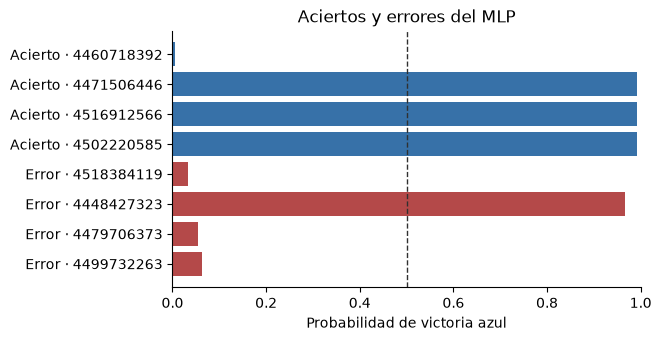

In [11]:
ejemplos = pd.DataFrame({
    "Partida": datos.iloc[indices_prueba]["gameId"].to_numpy(),
    "Oro azul menos rojo": variables.iloc[indices_prueba]["oro"].to_numpy(),
    "Ganador real": np.take(nombres_clases, y_prueba),
    "Ganador predicho": np.take(nombres_clases, pred_prueba_mlp),
    "Probabilidad de victoria azul": prob_prueba_mlp,
    "Acierto": y_prueba == pred_prueba_mlp,
})
ejemplos["Distancia al umbral"] = (ejemplos["Probabilidad de victoria azul"] - 0.50).abs()
ejemplos = ejemplos.nlargest(len(ejemplos), "Distancia al umbral")
muestra = pd.concat([ejemplos[ejemplos["Acierto"]].head(4), ejemplos[~ejemplos["Acierto"]].head(4)])
display(muestra.drop(columns="Distancia al umbral").round(3).reset_index(drop=True))
assert set(muestra["Acierto"]) == {True, False}

fig, ax = plt.subplots(figsize=(6.5, 3.3), layout="constrained")
posiciones = np.arange(len(muestra))
etiquetas_ejemplos = [f"{'Acierto' if acierto else 'Error'} · {partida}"
                       for acierto, partida in zip(muestra["Acierto"], muestra["Partida"])]
ax.barh(posiciones, muestra["Probabilidad de victoria azul"],
        color=np.where(muestra["Acierto"], "#3771a8", "#b44949"))
ax.axvline(0.50, color="#303030", linestyle="--", linewidth=1)
ax.set(yticks=posiciones, yticklabels=etiquetas_ejemplos, xlim=(0, 1),
       xlabel="Probabilidad de victoria azul", title="Aciertos y errores del MLP")
ax.invert_yaxis()
plt.show()

## 7. Análisis y conclusiones

Comparo el resultado del MLP con el punto de referencia para saber si la complejidad extra aportó algo en esta muestra. También reviso los errores porque el modelo solo ve los primeros diez minutos. Le faltan datos sobre las decisiones de equipo y los cambios de ventaja que ocurren después.

Como siguiente experimento, probaría con partidas de otros parches y rangos, separándolas por fecha si ese dato está disponible. Eso me permitiría medir si el rendimiento se mantiene cuando cambian las condiciones de juego.

In [12]:
fila_mlp = metricas_prueba.loc[nombre_elegido]
fila_referencia = metricas_prueba.loc["Regresión logística"]
diferencia_exactitud = 100 * (fila_mlp["Exactitud"] - fila_referencia["Exactitud"])
error_seguro = muestra.loc[~muestra["Acierto"]].iloc[0]
display(Markdown(
    f"Elegí **{nombre_elegido}** en la época **{int(ganador['Mejor época'])}**. "
    f"En prueba obtuve **{fila_mlp['Exactitud']:.2%} de exactitud**, "
    f"**{fila_mlp['F1 macro']:.4f} de F1 macro** y una pérdida de "
    f"**{fila_mlp['Pérdida']:.4f}**. La diferencia de exactitud frente a la "
    f"regresión logística fue de **{diferencia_exactitud:+.2f} puntos porcentuales**. "
    f"Con una sola partición de prueba, tomo esa diferencia como un resultado de esta muestra.\n\n"
    f"En la partida **{error_seguro['Partida']}**, el MLP estimó una probabilidad de "
    f"victoria azul de **{error_seguro['Probabilidad de victoria azul']:.1%}**. "
    f"El resultado observado fue **{error_seguro['Ganador real'].lower()}**. "
    "Este caso me mostró que una predicción segura también puede equivocarse."
))

Elegí **MLP de una capa** en la época **47**. En prueba obtuve **71.26% de exactitud**, **0.7125 de F1 macro** y una pérdida de **0.5350**. La diferencia de exactitud frente a la regresión logística fue de **-0.67 puntos porcentuales**. Con una sola partición de prueba, tomo esa diferencia como un resultado de esta muestra.

En la partida **4518384119**, el MLP estimó una probabilidad de victoria azul de **3.3%**. El resultado observado fue **gana azul**. Este caso me mostró que una predicción segura también puede equivocarse.